# Data Exploration

The purpose of this notebook is to understand what is in a recorded episode before doing any machine learning with it.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

EPISODES = Path("../data/raw/place_perturbed_400/episodes")

## One episode

Every episode is two files with the same name: an `.npz` with the arrays and a `.json` with everything else.

In [2]:
arrays = np.load(EPISODES / "episode_003.npz")
for key in arrays.files:
    print(f"{key:26s} {arrays[key].shape}  {arrays[key].dtype}")

observation.state          (316, 31)  float32
action                     (316, 31)  float32
timestamp                  (316,)  float64
info.phase                 (316,)  int16
privileged.object_pose     (316, 7)  float32


In [3]:
meta = json.loads((EPISODES / "episode_003.json").read_text())
print(list(meta.keys()))

['fps', 'frames', 'state_dim', 'state_names', 'slots', 'units', 'semantics', 'cameras', 'task', 'seed', 'episode', 'outcome', 'policy_info', 'randomisation', 'perturbation', 'quality', 'phases', 'privileged_keys', 'sim_model', 'controller', 'wall_s', 'policy', 'scenario', 'episode_index', 'generation']


`observation.state` and `action` have one row per frame and 31 columns. The JSON says what the columns are.

In [4]:
print(meta["slots"])
for i, name in enumerate(meta["state_names"]):
    print(i, name)

{'arm': [0, 14], 'hand': [14, 26], 'head': [26, 28], 'base': [28, 31]}
0 left_shoulder_pitch_joint
1 left_shoulder_roll_joint
2 left_shoulder_yaw_joint
3 left_elbow_joint
4 left_wrist_roll_joint
5 left_wrist_pitch_joint
6 left_wrist_yaw_joint
7 right_shoulder_pitch_joint
8 right_shoulder_roll_joint
9 right_shoulder_yaw_joint
10 right_elbow_joint
11 right_wrist_roll_joint
12 right_wrist_pitch_joint
13 right_wrist_yaw_joint
14 left_thumb_metacarpal_joint
15 left_thumb_proximal_joint
16 left_index_proximal_joint
17 left_middle_proximal_joint
18 left_ring_proximal_joint
19 left_pinky_proximal_joint
20 right_thumb_metacarpal_joint
21 right_thumb_proximal_joint
22 right_index_proximal_joint
23 right_middle_proximal_joint
24 right_ring_proximal_joint
25 right_pinky_proximal_joint
26 head_pan_joint
27 head_tilt_joint
28 base_vx
29 base_vy
30 base_wz


In [5]:
print(meta["task"])
print(meta["episode"]["arm"], meta["episode"]["object"], meta["episode"]["target"])
print(meta["outcome"])
print(meta["perturbation"])
print(meta["privileged_keys"])

place the blue can into the white tray
left blue_can white_tray
{'success': False, 'reason': 'blue_can is beside the white_tray', 'metrics': {'offset_x': 0.165, 'offset_y': -0.2468, 'height_m': -0.0122, 'released': 1.0, 'speed': 0.0}, 'first_success_s': None, 'frames': 316, 'seconds': 10.533, 'timed_out': False}
{'kind': 'drop', 'offset': [0.0126, -0.0554], 'at_s': 0.312, 'applied': True}
['privileged.object_pose', 'info.phase']


So in this episode the robot used the left arm, dropped the can and it ended up beside the tray.

`privileged.object_pose` and `info.phase` are marked as privileged: they only exist because this is a simulation. A real robot would not have them.

## What the hand does

Hand joints are columns 14 to 25: six for the left hand, then six for the right hand.

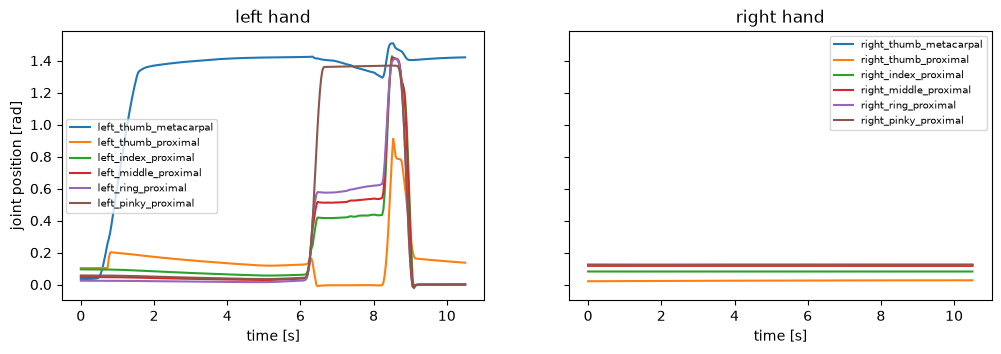

In [6]:
state = arrays["observation.state"]
t = arrays["timestamp"]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for col in range(14, 20):
    axes[0].plot(t, state[:, col], label=meta["state_names"][col].replace("_joint", ""))
axes[0].set_title("left hand")
for col in range(20, 26):
    axes[1].plot(t, state[:, col], label=meta["state_names"][col].replace("_joint", ""))
axes[1].set_title("right hand")
for ax in axes:
    ax.set_xlabel("time [s]")
    ax.legend(fontsize=7)
axes[0].set_ylabel("joint position [rad]")
plt.show()

Only the left hand moves, the right hand stays where it started.

What I think is happening in the left hand:
- the thumb swings over early (`thumb_metacarpal` goes to 1.4 and stays there)
- at about 6.3 s the fingers close. Index, middle and ring stop at 0.4 to 0.6, probably because the can is in the way
- at about 8.3 s they suddenly go to 1.4. I think this is the moment the can is gone and nothing stops the fingers anymore
- then the hand opens and the episode ends

So the finger positions while the hand is closed could say something about whether the object is still in the hand.